# TP: Predicción de abandono en estudiantes terciarios
**Instituto Tecnológico Beltrán - Árbol de decisión**

**Alumnos**: Gadiel mauri y Benjamin galeano

---


## Importar las librerías

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)


----
## Cargar y mirar los datos
Los datos de entrenamiento están en la hoja `PrediccionAbandonoTabla` (la otra hoja, `Sheet1`, está vacía).

In [4]:
archivo_train = "datos/TablaPrediccionAbandono-Entrenamiento.xlsx"
archivo_final = "datos/TablaPrediccionAbandono-DatosFinal.xlsx"

df = pd.read_excel(archivo_train, sheet_name="PrediccionAbandonoTabla")
df_final = pd.read_excel(archivo_final)

print("Entrenamiento:", df.shape)
print("DatosFinal:   ", df_final.shape)
df.head()

Entrenamiento: (100, 11)
DatosFinal:    (100, 10)


,edad,genero,carrera,PromedioPrimerCuatrimestre,CantMateriasAprobadasPrimerCuatrimestre,CantMateriasDesaprobadasPrimerCuatrimestre,AsistenciaPromedio(%),trabaja/NoTrabaja,DistanciaDomicilioAlInstituto(Kms),ActividadesExtracurriculares(Estudio),EstadoFinal
0,54,f,TECNICATURA SUPERIOR EN ADMINISTRACIÓN DE PYMES,7.44,3,6,66.32,Si,4,Si,Continúa
1,51,m,TECNICATURA SUPERIOR EN ADMINISTRACIÓN CONTABLE,7.00,7,7,50.64,No,15,No,Continúa
2,59,f,TECNICATURA SUPERIOR EN RADIOLOGIA,8.04,3,2,52.28,No,14,Si,Abandonó
3,29,m,TECNICATURA SUPERIOR EN RADIOLOGIA,8.41,2,3,41.76,No,14,No,Continúa
4,57,f,TECNICATURA SUPERIOR EN RADIOLOGIA,4.04,5,2,72.07,Si,9,Si,Abandonó


In [5]:
# Tipos de dato y valores nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   edad                                        100 non-null    int64  
 1   genero                                      100 non-null    object 
 2   carrera                                     100 non-null    object 
 3   PromedioPrimerCuatrimestre                  100 non-null    float64
 4   CantMateriasAprobadasPrimerCuatrimestre     100 non-null    int64  
 5   CantMateriasDesaprobadasPrimerCuatrimestre  100 non-null    int64  
 6   AsistenciaPromedio(%)                       100 non-null    float64
 7   trabaja/NoTrabaja                           100 non-null    object 
 8   DistanciaDomicilioAlInstituto(Kms)          100 non-null    int64  
 9   ActividadesExtracurriculares(Estudio)       100 non-null    object 
 10  EstadoFinal    

In [6]:
# Estadísticas de las columnas numéricas
df.describe().round(2)

,edad,PromedioPrimerCuatrimestre,CantMateriasAprobadasPrimerCuatrimestre,CantMateriasDesaprobadasPrimerCuatrimestre,AsistenciaPromedio(%),DistanciaDomicilioAlInstituto(Kms)
count,100.00,100.00,100.00,100.00,100.00,100.00
mean,39.60,7.11,3.84,4.36,69.01,10.42
std,12.31,1.72,1.79,1.66,17.97,5.42
min,18.00,4.04,1.00,1.00,41.76,1.00
25%,28.00,5.78,2.75,3.00,52.28,6.00
50%,40.00,7.38,4.00,4.00,68.68,10.00
75%,50.00,8.36,5.00,6.00,86.91,15.00
max,60.00,9.99,7.00,7.00,99.01,20.00


In [7]:
# Balance de la variable objetivo: ¿cuántos abandonan y cuántos continúan?
print(df["EstadoFinal"].value_counts())
print()
print(df["EstadoFinal"].value_counts(normalize=True).round(3))

EstadoFinal
Abandonó    54
Continúa    46
Name: count, dtype: int64

EstadoFinal
Abandonó    0.54
Continúa    0.46
Name: proportion, dtype: float64


In [8]:
# Valores distintos en las columnas de texto
for col in ["genero", "carrera", "trabaja/NoTrabaja", "ActividadesExtracurriculares(Estudio)", "EstadoFinal"]:
    print(col, "->", df[col].unique())
    print()

genero -> ['f' 'm']

carrera -> ['TECNICATURA SUPERIOR EN ADMINISTRACIÓN DE PYMES'
 'TECNICATURA SUPERIOR EN ADMINISTRACIÓN CONTABLE'
 'TECNICATURA SUPERIOR EN RADIOLOGIA'
 'TECNICATURA SUPERIOR EN DISEÑO INDUSTRIAL'
 'TECNICATURA SUPERIOR EN ENFERMERÍA'
 'TECNICATURA SUPERIOR EN CIENCIA DE DATOS E INTELIGENCIA ARTIFICIAL'
 'TÉCNICATURA SUPERIOR EN HIGIENE Y SEGURIDAD EN EL TRABAJO'
 'TECNICATURA SUPERIOR EN ANÁLISIS DE SISTEMAS'
 'TECNICATURA SUPERIOR EN COMUNICACIÓN MULTIMEDIAL']

trabaja/NoTrabaja -> ['Si' 'No']

ActividadesExtracurriculares(Estudio) -> ['Si' 'No']

EstadoFinal -> ['Continúa' 'Abandonó']



-----
## Limpiar y preparar los datos
El árbol necesita números, no texto. Hacemos tres cosas:
1. Renombrar las columnas con nombres cortos.
2. Convertir `Si/No` y `Abandonó/Continúa` a 1/0.
3. Convertir `genero` y `carrera` en columnas 0/1 (*one-hot encoding*).

In [9]:
nombres = {
    "PromedioPrimerCuatrimestre": "promedio",
    "CantMateriasAprobadasPrimerCuatrimestre": "aprobadas",
    "CantMateriasDesaprobadasPrimerCuatrimestre": "desaprobadas",
    "AsistenciaPromedio(%)": "asistencia",
    "trabaja/NoTrabaja": "trabaja",
    "DistanciaDomicilioAlInstituto(Kms)": "distancia_km",
    "ActividadesExtracurriculares(Estudio)": "extracurriculares",
}

def preparar(d):
    d = d.rename(columns=nombres).copy()
    d["genero"] = d["genero"].str.strip().str.lower()
    d["carrera"] = d["carrera"].str.strip().str.upper()
    d["trabaja"] = d["trabaja"].str.strip().str.lower().map({"si": 1, "no": 0})
    d["extracurriculares"] = d["extracurriculares"].str.strip().str.lower().map({"si": 1, "no": 0})
    return d

df_p = preparar(df)
df_p["abandono"] = df_p["EstadoFinal"].str.strip().str.lower().map({"abandonó": 1, "continúa": 0})

print("Nulos tras la conversión (deben ser 0):")
print(df_p[["trabaja", "extracurriculares", "abandono"]].isna().sum())
print("Duplicados:", df_p.duplicated().sum())

Nulos tras la conversión (deben ser 0):
trabaja              0
extracurriculares    0
abandono             0
dtype: int64
Duplicados: 0


In [10]:
# Exploración rápida: tasa de abandono según algunas variables
print(df_p.groupby("trabaja")["abandono"].mean().round(3))
print()
print(df_p.groupby("extracurriculares")["abandono"].mean().round(3))
print()
print(df_p.groupby("carrera")["abandono"].agg(["mean", "count"]).round(3))

trabaja
0    0.561
1    0.512
Name: abandono, dtype: float64

extracurriculares
0    0.511
1    0.566
Name: abandono, dtype: float64

                                                     mean  count
carrera                                                         
TECNICATURA SUPERIOR EN ADMINISTRACIÓN CONTABLE     0.600     15
TECNICATURA SUPERIOR EN ADMINISTRACIÓN DE PYMES     0.417     12
TECNICATURA SUPERIOR EN ANÁLISIS DE SISTEMAS        0.600     10
TECNICATURA SUPERIOR EN CIENCIA DE DATOS E INTE...  0.750     12
TECNICATURA SUPERIOR EN COMUNICACIÓN MULTIMEDIAL    0.444      9
TECNICATURA SUPERIOR EN DISEÑO INDUSTRIAL           0.667     12
TECNICATURA SUPERIOR EN ENFERMERÍA                  0.364     11
TECNICATURA SUPERIOR EN RADIOLOGIA                  0.385     13
TÉCNICATURA SUPERIOR EN HIGIENE Y SEGURIDAD EN ...  0.667      6


---

## Graficos

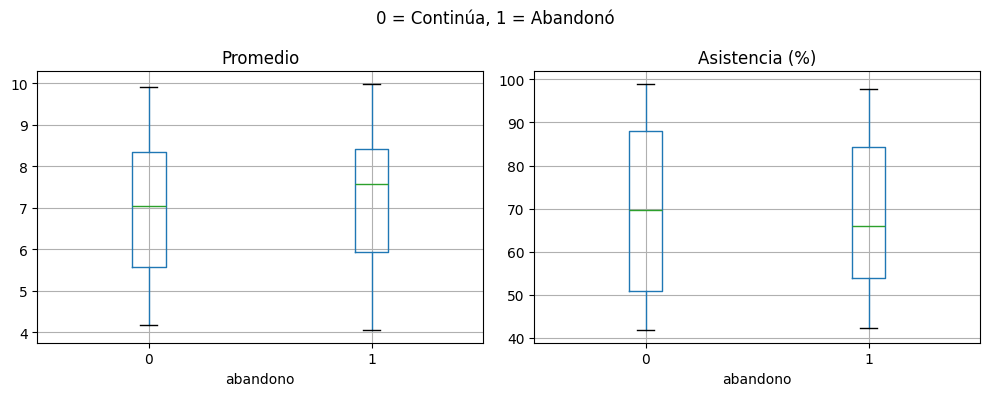

In [11]:
# Gráfico: promedio y asistencia según si abandonó o continúa
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df_p.boxplot(column="promedio", by="abandono", ax=ax[0])
df_p.boxplot(column="asistencia", by="abandono", ax=ax[1])
ax[0].set_title("Promedio"); ax[1].set_title("Asistencia (%)")
plt.suptitle("0 = Continúa, 1 = Abandonó")
plt.tight_layout()
plt.show()

In [12]:
# One-hot encoding de genero y carrera
y = df_p["abandono"]
X = df_p.drop(columns=["EstadoFinal", "abandono"])
X = pd.get_dummies(X, columns=["genero", "carrera"], dtype=int)

print(X.shape)
X.head()

(100, 19)


,edad,promedio,aprobadas,desaprobadas,asistencia,trabaja,distancia_km,extracurriculares,genero_f,genero_m,carrera_TECNICATURA SUPERIOR EN ADMINISTRACIÓN CONTABLE,carrera_TECNICATURA SUPERIOR EN ADMINISTRACIÓN DE PYMES,carrera_TECNICATURA SUPERIOR EN ANÁLISIS DE SISTEMAS,carrera_TECNICATURA SUPERIOR EN CIENCIA DE DATOS E INTELIGENCIA ARTIFICIAL,carrera_TECNICATURA SUPERIOR EN COMUNICACIÓN MULTIMEDIAL,carrera_TECNICATURA SUPERIOR EN DISEÑO INDUSTRIAL,carrera_TECNICATURA SUPERIOR EN ENFERMERÍA,carrera_TECNICATURA SUPERIOR EN RADIOLOGIA,carrera_TÉCNICATURA SUPERIOR EN HIGIENE Y SEGURIDAD EN EL TRABAJO
0,54,7.44,3,6,66.32,1,4,1,1,0,0,1,0,0,0,0,0,0,0
1,51,7.00,7,7,50.64,0,15,0,0,1,1,0,0,0,0,0,0,0,0
2,59,8.04,3,2,52.28,0,14,1,1,0,0,0,0,0,0,0,0,1,0
3,29,8.41,2,3,41.76,0,14,0,0,1,0,0,0,0,0,0,0,1,0
4,57,4.04,5,2,72.07,1,9,1,1,0,0,0,0,0,0,0,0,1,0


------
## Separar entrenamiento y prueba
Con 100 filas separamos el 80% para entrenar y el 20% para probar. `stratify=y` mantiene la misma proporción de abandono en ambos grupos.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Abandono en train:", y_train.mean().round(3), "| en test:", y_test.mean().round(3))

Train: (80, 19) | Test: (20, 19)
Abandono en train: 0.538 | en test: 0.55


-----
## Entrenar el árbol de decisión
Limitamos la profundidad (`max_depth`) y el tamaño mínimo de las hojas (`min_samples_leaf`). Con pocos datos, un árbol sin límites memoriza (sobreajuste).

In [26]:
arbol = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42)
arbol.fit(X_train, y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [ ]:
# Probar varias combinaciones de hiperparámetros con validación cruzada
param_grid = {
    "max_depth": [2, 3, 4, 5],
    "min_samples_leaf": [3, 5, 8, 10],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring="f1")
grid.fit(X_train, y_train)
print("Mejores parámetros:", grid.best_params_)
print("F1 en validación cruzada:", round(grid.best_score_, 3))

Mejores parámetros: {'max_depth': 2, 'min_samples_leaf': 3}
F1 en validación cruzada: 0.629


In [ ]:
arbol = grid.best_estimator_

## Evaluar el modelo con el conjunto de prueba

El **recall de la clase 1 (Abandonó)**: es la proporción de estudiantes que abandonaron y el modelo logró detectar.

In [29]:
y_pred = arbol.predict(X_test)

print("Accuracy train:", round(arbol.score(X_train, y_train), 3))
print("Accuracy test: ", round(accuracy_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=["Continúa", "Abandonó"], zero_division=0))

Accuracy train: 0.65
Accuracy test:  0.55

              precision    recall  f1-score   support

    Continúa       0.50      0.44      0.47         9
    Abandonó       0.58      0.64      0.61        11

    accuracy                           0.55        20
   macro avg       0.54      0.54      0.54        20
weighted avg       0.55      0.55      0.55        20



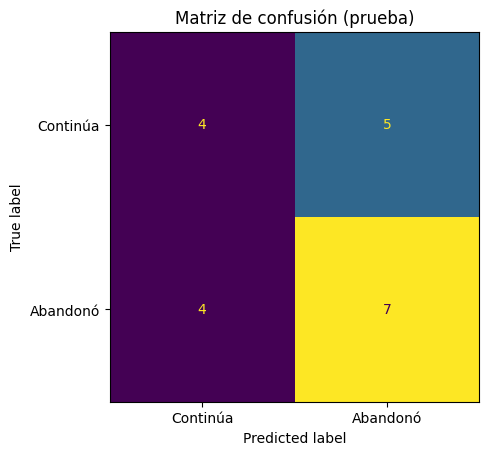

In [30]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Continúa", "Abandonó"]).plot(colorbar=False)
plt.title("Matriz de confusión (prueba)")
plt.show()

In [31]:
# Con tan pocos datos, la validación cruzada da una estimación más estable
scores = cross_val_score(arbol, X, y, cv=5)
print("Accuracy por fold:", scores.round(3))
print("Promedio:", scores.mean().round(3))

Accuracy por fold: [0.25 0.5  0.5  0.5  0.45]
Promedio: 0.44


## Interpretar el árbol
¿Qué variables usa el árbol para decidir? Importancia alta = más peso en las divisiones.

edad         0.451
promedio     0.407
aprobadas    0.142
dtype: float64


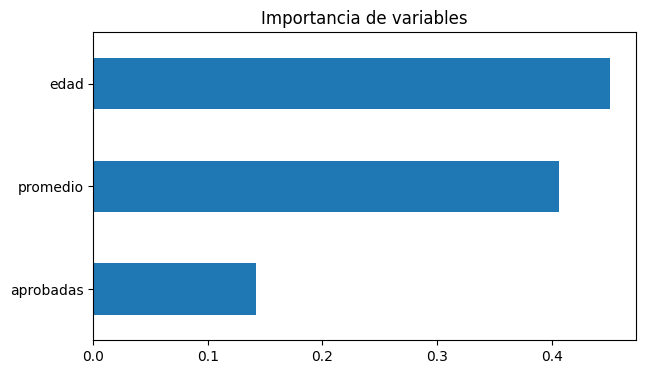

In [32]:
importancias = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importancias[importancias > 0].round(3))

importancias[importancias > 0].sort_values().plot(kind="barh", figsize=(7, 4))
plt.title("Importancia de variables")
plt.show()

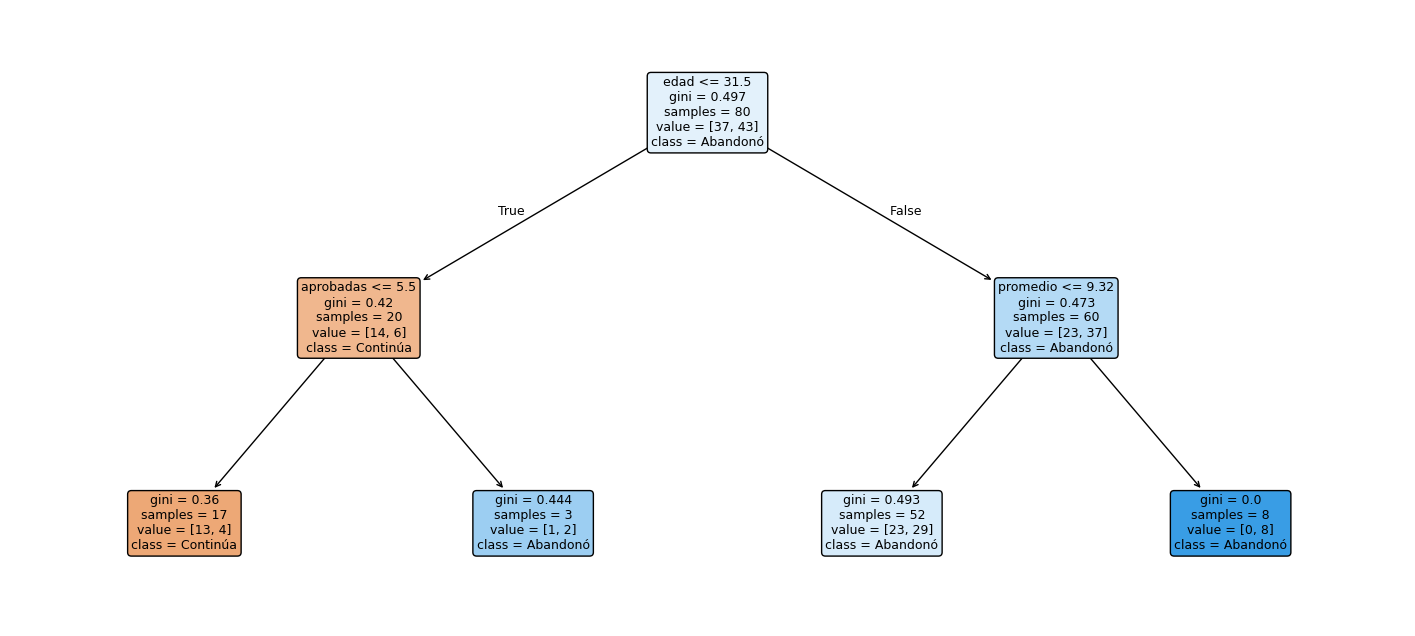

In [33]:
plt.figure(figsize=(18, 8))
plot_tree(arbol, feature_names=X.columns, class_names=["Continúa", "Abandonó"],
          filled=True, rounded=True, fontsize=9)
plt.show()

In [34]:
# Las mismas reglas, en texto
print(export_text(arbol, feature_names=list(X.columns)))

|--- edad <= 31.50
|   |--- aprobadas <= 5.50
|   |   |--- class: 0
|   |--- aprobadas >  5.50
|   |   |--- class: 1
|--- edad >  31.50
|   |--- promedio <= 9.32
|   |   |--- class: 1
|   |--- promedio >  9.32
|   |   |--- class: 1



## Predecir con el archivo DatosFinal
Aplicamos exactamente la misma preparación y alineamos las columnas con las del entrenamiento.

In [35]:
dfin = preparar(df_final)
Xf = pd.get_dummies(dfin, columns=["genero", "carrera"], dtype=int)
Xf = Xf.reindex(columns=X.columns, fill_value=0)   # mismas columnas y orden que en entrenamiento

pred = arbol.predict(Xf)
proba = arbol.predict_proba(Xf)[:, 1]

resultado = df_final.copy()
resultado["Prediccion"] = np.where(pred == 1, "Abandonó", "Continúa")
resultado["Prob_abandono"] = proba.round(3)

print(resultado["Prediccion"].value_counts())
resultado.head(10)

Prediccion
Abandonó    78
Continúa    22
Name: count, dtype: int64


,edad,genero,carrera,PromedioPrimerCuatrimestre,CantMateriasAprobadasPrimerCuatrimestre,CantMateriasDesaprobadasPrimerCuatrimestre,AsistenciaPromedio(%),trabaja/NoTrabaja,DistanciaDomicilioAlInstituto(Kms),ActividadesExtracurriculares(Estudio),Prediccion,Prob_abandono
0,60,m,TECNICATURA SUPERIOR EN ANÁLISIS DE SISTEMAS,9.54,5,1,55.44,No,4,No,Abandonó,1.000
1,60,m,TECNICATURA SUPERIOR EN ADMINISTRACIÓN CONTABLE,4.17,5,2,64.72,No,6,No,Abandonó,0.558
2,60,m,TECNICATURA SUPERIOR EN ADMINISTRACIÓN DE PYMES,6.24,3,5,41.23,No,6,Si,Abandonó,0.558
3,59,m,TECNICATURA SUPERIOR EN CIENCIA DE DATOS E INT...,8.07,2,4,72.50,No,5,No,Abandonó,0.558
4,59,m,TECNICATURA SUPERIOR EN COMUNICACIÓN MULTIMEDIAL,6.60,5,1,53.59,Si,18,No,Abandonó,0.558
5,59,f,TECNICATURA SUPERIOR EN ADMINISTRACIÓN DE PYMES,8.78,1,2,85.04,No,16,No,Abandonó,0.558
6,58,f,TECNICATURA SUPERIOR EN CIENCIA DE DATOS E INT...,6.49,5,7,81.69,Si,11,Si,Abandonó,0.558
7,58,f,TECNICATURA SUPERIOR EN RADIOLOGIA,6.30,3,2,60.29,No,3,No,Abandonó,0.558
8,58,m,TECNICATURA SUPERIOR EN ANÁLISIS DE SISTEMAS,9.58,3,6,48.57,No,3,No,Abandonó,1.000
9,57,f,TÉCNICATURA SUPERIOR EN HIGIENE Y SEGURIDAD EN...,5.68,4,2,69.59,No,4,Si,Abandonó,0.558


In [36]:
resultado.to_excel("Predicciones_DatosFinal.xlsx", index=False)
print("Guardado: Predicciones_DatosFinal.xlsx")

Guardado: Predicciones_DatosFinal.xlsx


## Conclusiones

### 1. Preparación de los datos
Se trabajó con 100 estudiantes de entrenamiento, sin valores nulos ni duplicados. La variable objetivo estaba relativamente balanceada (54% abandonó, 46% continúa). Las variables de texto se convirtieron a formato numérico (Si/No a 1/0 y one-hot encoding para género y carrera), y se separó el 80% de los datos para entrenamiento y el 20% para prueba, manteniendo la proporción de clases.

### 2. Modelo
Se entrenó un árbol de decisión con profundidad limitada (`max_depth=2`, seleccionada mediante validación cruzada) para reducir el riesgo de sobreajuste, dado el tamaño reducido de la muestra.

### 3. Evaluación
En el conjunto de prueba (20 estudiantes) el modelo obtuvo una accuracy de 0,55, un recall de 0,64 y una precision de 0,58 para la clase "Abandonó". Esto significa que detectó a 7 de los 11 estudiantes que abandonaron, aunque marcó como en riesgo a 5 estudiantes que finalmente continuaron. El desempeño es modesto: la accuracy es similar a la de predecir "Abandonó" para todos los casos (0,55), por lo que el modelo no supera claramente a una estrategia trivial.

### 4. Variables importantes
El árbol utilizó solo tres variables: edad (primera división), materias aprobadas y promedio del primer cuatrimestre. Se observó mayor tendencia al abandono en estudiantes mayores de 31 años. Las demás variables (asistencia, materias desaprobadas, distancia, situación laboral y actividades extracurriculares) no fueron utilizadas por este árbol, lo cual no implica que carezcan de relación con el abandono, sino que con estos datos no aportaron mejores divisiones.

### 5. Limitaciones
- Muestra pequeña (100 estudiantes) y conjunto de prueba de solo 20: los resultados son inestables y una variación de pocos casos cambia las métricas.
- Algunas hojas del árbol tienen muy pocos estudiantes (por ejemplo, 3 y 8), por lo que sus reglas pueden deberse al azar. En particular, que un promedio alto (> 9,32) se asocie al abandono es contraintuitivo y no debe tomarse como un hallazgo confiable.
- El nodo con más estudiantes (52 de 80) tiene una distribución casi pareja (56% abandona), donde el modelo prácticamente no distingue.
- La importancia de las variables indica asociación en estos datos, no causalidad.

